PCA machine learning -Breast cancer dataset

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

print(cancer.DESCR) # Print the data set description

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [2]:
df = pd.DataFrame(data=cancer.data, columns =cancer.feature_names)

In [15]:
df['target'] = cancer.target
target =  df['target'].value_counts()#.unique()
    
target.index= ['malignant', 'benign']
    

In [3]:
cancer.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [4]:
df.shape

(569, 30)

In [5]:
df.index

RangeIndex(start=0, stop=569, step=1)

In [ ]:
from sklearn.model_selection import train_test_split



In [ ]:
y = df.loc[:,df.columns[30]]
y

In [ ]:
X = df.loc[:,df.columns[0:30]]
X

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 143, train_size= 426,random_state=0)

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
X_scaled = StandardScaler().fit_transform(df)

In [9]:
pca= PCA(n_components= 3)

In [12]:
X_pca = pca.fit_transform(X_scaled)

In [13]:
df_pca = pd.DataFrame(X_pca, columns=['Comp-1', 'Comp-2','Comp-3'])

In [16]:
df_pca['Type of Tumor'] = df['target']

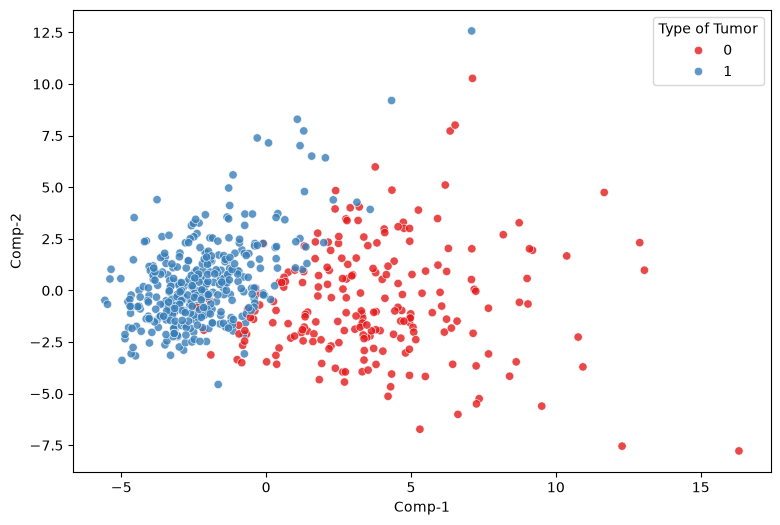

In [17]:
plt.figure(figsize=(9,6))
sns.scatterplot(
    x='Comp-1',
    y='Comp-2',
   
    hue='Type of Tumor',
    data=df_pca,
    palette='Set1',
    alpha=0.8)
plt.show()

In [18]:
import plotly.express as px

In [19]:
fig = px.scatter_3d(df_pca, x='Comp-1', y='Comp-2', z= 'Comp-3',color='Type of Tumor')
fig.show()